# Patient risk: preparing real ICU data, and the NEWS2 baseline

**Data:** PhysioNet / Computing in Cardiology Challenge 2019, *Early Prediction of Sepsis from Clinical Data*
(Reyna et al., Critical Care Medicine, 2019): about 40,000 ICU patients from **two separate hospital systems**,
one row per patient per hour.

**What this notebook does:**
1. Load both hospital systems.
2. Define the prediction target: **"sepsis will be recognised within the next 6 hours"**.
3. Keep only what MedTwin measures (vital signs, age, time in the ICU), fill gaps, and add **trend** features.
4. Split by **patient** (never by row), within each hospital system.
5. Score **NEWS2**, the standard early warning score, as the baseline the model must beat (Day 25).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

DATA, RESULTS = Path("../data/physionet2019"), Path("../results")
RESULTS.mkdir(exist_ok=True)
RAW = DATA / "all_hours.parquet"

# Reading 40,000 small files takes a few minutes, so they're combined once into one fast file.
if RAW.exists():
    raw = pd.read_parquet(RAW)
else:
    frames = []
    for hospital in ("A", "B"):
        for file in sorted((DATA / f"training_set{hospital}").glob("*.psv")):
            frame = pd.read_csv(file, sep="|")
            frame.insert(0, "patient", f"{hospital}{file.stem[1:]}")
            frame.insert(1, "hospital", hospital)
            frames.append(frame)
    raw = pd.concat(frames, ignore_index=True)
    raw.to_parquet(RAW)

patients = raw.groupby("patient").agg(hospital=("hospital", "first"), hours=("ICULOS", "max"), sepsis=("SepsisLabel", "max"))
overview = patients.groupby("hospital").agg(patients=("hours", "size"), median_hours_in_icu=("hours", "median"),
                                             sepsis_patients=("sepsis", "sum"))
overview["sepsis_%"] = (100 * overview["sepsis_patients"] / overview["patients"]).round(1)
print(f"{len(raw):,} patient-hours from {len(patients):,} patients")
overview

1,552,210 patient-hours from 40,336 patients


,patients,median_hours_in_icu,sepsis_patients,sepsis_%
hospital,,,,
A,20336,40.0,1790,8.8
B,20000,38.0,1142,5.7


## Only what MedTwin measures

The data also has 26 laboratory values, but MedTwin's patients only have **vital signs** (plus age and time in
the ICU). The model has to run on MedTwin's live patients, so it uses only those. How often is each vital missing?

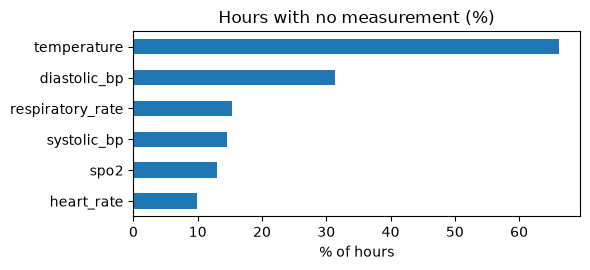

heart_rate           9.9
spo2                13.1
systolic_bp         14.6
respiratory_rate    15.4
diastolic_bp        31.3
temperature         66.2
dtype: float64

In [2]:
VITALS = {"HR": "heart_rate", "O2Sat": "spo2", "Temp": "temperature", "SBP": "systolic_bp",
          "DBP": "diastolic_bp", "Resp": "respiratory_rate"}
missing = raw[list(VITALS)].isna().mean().rename(index=VITALS).sort_values() * 100
ax = missing.plot.barh(figsize=(6, 2.8), title="Hours with no measurement (%)")
ax.set_xlabel("% of hours")
plt.tight_layout()
plt.savefig(RESULTS / "risk_missing_values.png", dpi=150)
plt.show()
missing.round(1)

## The target: "sepsis will be recognised within the next 6 hours"

In this dataset `SepsisLabel` turns to 1 **six hours before** doctors recognised sepsis. So for each hour:

* **1** = sepsis will be recognised within the next 6 hours (the early-warning window),
* **0** = no sepsis coming in the next 6 hours.

Hours **after** sepsis was recognised are dropped: by then the patient is already being treated, so a warning
would be too late to help.

In [3]:
df = raw[["patient", "hospital", "ICULOS", "Age", "Gender", "FiO2", "SepsisLabel", *VITALS]].rename(columns=VITALS)
df = df.rename(columns={"ICULOS": "hours_in_icu", "Age": "age", "Gender": "male"})
first_label = df[df["SepsisLabel"] == 1].groupby("patient")["hours_in_icu"].min()
df["warning_from"] = df["patient"].map(first_label)  # first hour of the 6-hour window, NaN for patients without sepsis
recognised_at = df["warning_from"] + 6
df = df[df["warning_from"].isna() | (df["hours_in_icu"] < recognised_at)].copy()
df["target"] = (df["warning_from"].notna() & (df["hours_in_icu"] >= df["warning_from"])).astype(int)
print(f"{len(df):,} hours kept · {df['target'].mean() * 100:.2f}% of them are in a 6-hour warning window")

1,541,845 hours kept · 1.14% of them are in a 6-hour warning window


## Filling gaps, and trend features

* **Gaps:** a missing value is filled with the patient's **last known value**, and the model is told **how many
  hours ago** that value was really measured.
* **Trends:** deterioration is about *change*, so each vital also gets its change over the last 6 hours and its
  6-hour average, minimum and maximum.
* **Oxygen:** the share of oxygen in the air the patient breathes (FiO2) is recorded only now and then; above 21%
  means the patient is on extra oxygen. NEWS2 uses this.

In [4]:
df = df.sort_values(["patient", "hours_in_icu"]).reset_index(drop=True)
by_patient = df.groupby("patient", sort=False)

for vital in VITALS.values():
    measured_at = df["hours_in_icu"].where(df[vital].notna())
    df[f"{vital}_hours_since"] = df["hours_in_icu"] - measured_at.groupby(df["patient"]).ffill()
    df[vital] = by_patient[vital].ffill()

by_patient = df.groupby("patient", sort=False)  # regroup with the filled values
for vital in VITALS.values():
    window = by_patient[vital].rolling(6, min_periods=1)
    df[f"{vital}_mean_6h"] = window.mean().reset_index(level=0, drop=True)
    df[f"{vital}_min_6h"] = window.min().reset_index(level=0, drop=True)
    df[f"{vital}_max_6h"] = window.max().reset_index(level=0, drop=True)
    df[f"{vital}_change_6h"] = df[vital] - by_patient[vital].shift(6)

df["on_oxygen"] = (by_patient["FiO2"].ffill() > 0.21).astype(int)
FEATURES = (["age", "male", "hours_in_icu", "on_oxygen", *VITALS.values()]
            + [f"{v}_{s}" for v in VITALS.values() for s in ("hours_since", "mean_6h", "min_6h", "max_6h", "change_6h")])
print(len(FEATURES), "features")
df[["patient", "hours_in_icu", "heart_rate", "heart_rate_change_6h", "heart_rate_hours_since", "target"]].head(8)

40 features


,patient,hours_in_icu,heart_rate,heart_rate_change_6h,heart_rate_hours_since,target
0,A000001,1,NaN,NaN,NaN,0
1,A000001,2,97.0,NaN,0.0,0
2,A000001,3,89.0,NaN,0.0,0
3,A000001,4,90.0,NaN,0.0,0
4,A000001,5,103.0,NaN,0.0,0
5,A000001,6,110.0,NaN,0.0,0
6,A000001,7,108.0,NaN,0.0,0
7,A000001,8,106.0,9.0,0.0,0


## NEWS2: the baseline to beat

**NEWS2** (National Early Warning Score 2, Royal College of Physicians, 2017) is the early warning score used
in hospitals in the UK and many other countries. Each vital sign earns 0–3 points depending on how far it is from
normal; the points are added up. A total of **5 or more** calls for an urgent review; **7 or more** for an
emergency response. (Consciousness level isn't in this data, so it counts as normal.)

In [5]:
def points(values, bands):
    """bands: list of (condition, points); the first matching condition wins, otherwise 0."""
    return np.select([condition(values) for condition, _ in bands], [p for _, p in bands], default=0)


def news2(frame):
    rr, spo2, sbp = frame["respiratory_rate"], frame["spo2"], frame["systolic_bp"]
    hr, temp = frame["heart_rate"], frame["temperature"]
    return (
        points(rr, [(lambda x: x <= 8, 3), (lambda x: x <= 11, 1), (lambda x: x <= 20, 0), (lambda x: x <= 24, 2), (lambda x: x >= 25, 3)])
        + points(spo2, [(lambda x: x <= 91, 3), (lambda x: x <= 93, 2), (lambda x: x <= 95, 1)])
        + 2 * frame["on_oxygen"]
        + points(sbp, [(lambda x: x <= 90, 3), (lambda x: x <= 100, 2), (lambda x: x <= 110, 1), (lambda x: x >= 220, 3)])
        + points(hr, [(lambda x: x <= 40, 3), (lambda x: x <= 50, 1), (lambda x: x <= 90, 0), (lambda x: x <= 110, 1), (lambda x: x <= 130, 2), (lambda x: x >= 131, 3)])
        + points(temp, [(lambda x: x <= 35.0, 3), (lambda x: x <= 36.0, 1), (lambda x: x <= 38.0, 0), (lambda x: x <= 39.0, 1), (lambda x: x >= 39.1, 2)])
    )


df["news2"] = news2(df)
df["news2"].describe().round(2)

count    1541845.00
mean           2.98
std            2.28
min            0.00
25%            1.00
50%            3.00
75%            4.00
max           17.00
Name: news2, dtype: float64

In [6]:
# Split by patient: every patient goes wholly into training (80%) or testing (20%), within their hospital system.
patient_split = df[["patient"]].drop_duplicates()
patient_split["split"] = np.where(np.random.default_rng(42).random(len(patient_split)) < 0.8, "train", "test")
df = df.merge(patient_split, on="patient")

rows = []
for name, part in [("Hospital A", df[(df.hospital == "A") & (df.split == "test")]),
                   ("Hospital B", df[(df.hospital == "B") & (df.split == "test")]),
                   ("Both", df[df.split == "test"])]:
    row = {"test set": name, "hours": len(part), "warning hours %": round(100 * part["target"].mean(), 2),
           "AUROC": round(roc_auc_score(part["target"], part["news2"]), 3),
           "AUPRC": round(average_precision_score(part["target"], part["news2"]), 3)}
    for threshold in (5, 7):
        flagged = part["news2"] >= threshold
        row[f"NEWS2≥{threshold}: catches"] = f"{100 * flagged[part['target'] == 1].mean():.0f}%"
        row[f"NEWS2≥{threshold}: alarms that are right"] = f"{100 * part.loc[flagged, 'target'].mean():.1f}%"
    rows.append(row)
baseline = pd.DataFrame(rows).set_index("test set")
baseline.to_csv(RESULTS / "risk_news2_baseline.csv")
baseline.T

test set,Hospital A,Hospital B,Both
hours,158049,151738,309787
warning hours %,1.4,0.81,1.11
AUROC,0.627,0.687,0.663
AUPRC,0.021,0.018,0.019
NEWS2≥5: catches,47%,43%,46%
NEWS2≥5: alarms that are right,2.2%,1.9%,2.1%
NEWS2≥7: catches,18%,18%,18%
NEWS2≥7: alarms that are right,2.6%,2.6%,2.6%


**Reading the table:**

* **AUROC** (0.5 = coin toss, 1.0 = perfect): if you pick one warning-window hour and one normal hour at random,
  how often does the score rank the warning hour higher?
* **AUPRC**: like AUROC but focused on the rare warning hours. Compare it with the **warning hours %**, which is
  what random guessing would score.
* **Catches** (sensitivity) and **alarms that are right** (precision) at the standard NEWS2 trigger levels.

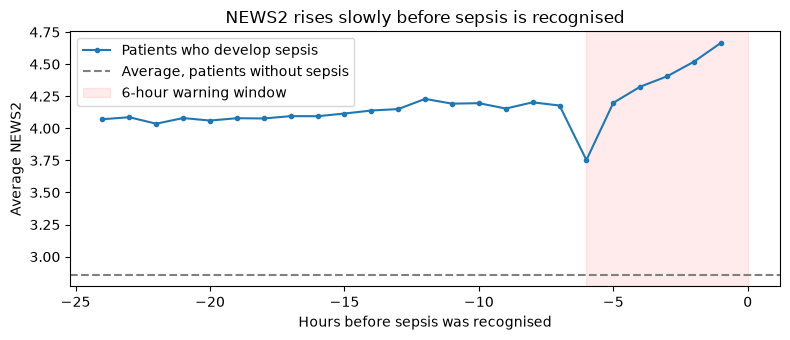

In [7]:
# Does NEWS2 rise before sepsis is recognised? Average score by hours before recognition.
septic = df[df["warning_from"].notna()].copy()
septic["hours_before"] = septic["warning_from"] + 6 - septic["hours_in_icu"]
curve = septic[septic["hours_before"].between(1, 24)].groupby("hours_before")["news2"].mean()
normal_level = df.loc[df["warning_from"].isna(), "news2"].mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(-curve.index, curve.values, marker="o", ms=3, label="Patients who develop sepsis")
ax.axhline(normal_level, color="grey", ls="--", label="Average, patients without sepsis")
ax.axvspan(-6, 0, color="red", alpha=0.08, label="6-hour warning window")
ax.set_xlabel("Hours before sepsis was recognised")
ax.set_ylabel("Average NEWS2")
ax.set_title("NEWS2 rises slowly before sepsis is recognised")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS / "risk_news2_before_sepsis.png", dpi=150)
plt.show()

In [8]:
OUT = DATA / "risk_features.parquet"
df[["patient", "hospital", "split", "target", "news2", *FEATURES]].to_parquet(OUT)
pd.Series(FEATURES).to_csv(DATA / "risk_feature_names.csv", index=False, header=False)
print(f"Saved {len(df):,} rows and {len(FEATURES)} features to {OUT}")

Saved 1,541,845 rows and 40 features to ..\data\physionet2019\risk_features.parquet


## Notes for the report

* **Real data:** PhysioNet 2019 is real ICU data from two hospital systems; MedTwin's own patients are simulated.
  Training on real data is what makes the risk model's results meaningful outside the simulator.
* **Same features as MedTwin:** only the six vital signs, age, sex, time in the ICU and whether the patient is on
  oxygen, so the trained model can score MedTwin's live patients unchanged.
* **Patient-level splits** prevent the model from recognising a patient it has already seen.
* **NEWS2 limitation:** consciousness isn't recorded in this data, and supplemental oxygen is inferred from FiO2.